# Global Financial Markets Dashboard
## SQL Analysis of Historical Financial Market Data
### Objective

This notebook analyzes historical financial market data stored in a SQLite database. Using SQL queries and Python, it explores trading activity, price behavior, returns, trading volume, and volatility across multiple financial assets.

The goal is to transform raw market data into meaningful business insights that can later be visualized in an interactive Tableau dashboard.

Tools Used

* Python
* SQLite
* SQL
* Pandas
* Matplotlib

### 1. Connect to the SQLite Database

The cleaned market data produced by the ETL pipeline is stored in a SQLite database. This section establishes a connection to the database so SQL queries can be executed directly from Python.

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("../data/database/market_data.db")
if not DB_PATH.exists():
    raise FileNotFoundError(
        "Database not found. Run `python main.py` (or notebook 01) first to create it."
    )

connection = sqlite3.connect(DB_PATH)

The database connection was successfully established and is ready for analysis.

### 2. Trading Days Analysis

The first step is to verify the completeness of the dataset by counting the number of trading days available for each financial asset.

In [2]:
#amount of trading days for each ticker
query = """
SELECT
    Ticker,
    COUNT(*) AS [Trading Days]
FROM market_data
GROUP BY Ticker;
"""

trading_days_df= pd.read_sql(query, connection)
trading_days_df

,Ticker,Trading Days
0,AAPL,252
1,BTC-USD,366
2,CL=F,252
3,ETH-USD,366
4,EURUSD=X,260
5,GC=F,252
6,MSFT,252
7,NVDA,252
8,^GSPC,252
9,^IXIC,252


Most assets contain a similar number of observations, indicating that the ETL pipeline collected the data consistently. Cryptocurrencies contain additional observations because they trade seven days per week.

### 3. Closing Price Analysis

**Highest and Lowest Closing Prices**

This query identifies the highest and lowest closing prices recorded for each asset during the observation period.

In [3]:

#highest and lowest closing prices for each ticker
query = """
SELECT
    Ticker,
    MAX(Close) AS [Highest Closing Price],
    MIN(Close) AS [Lowest Closing Price]
FROM market_data
GROUP BY Ticker
ORDER BY MAX(Close) DESC;
""" 
closing_price_extremes_df = pd.read_sql(query, connection)
closing_price_extremes_df

,Ticker,Highest Closing Price,Lowest Closing Price
0,BTC-USD,124752.531250,58558.859375
1,^IXIC,27093.900391,20650.130859
2,^GSPC,7609.779785,6238.009766
3,GC=F,5318.399902,3293.199951
4,ETH-USD,4831.348633,1564.816650
5,MSFT,542.070007,352.829987
6,AAPL,333.739990,202.380005
7,NVDA,235.740005,165.169998
8,CL=F,112.949997,55.270000
9,EURUSD=X,1.201764,1.135422


Closing prices vary substantially across asset classes due to differences in price scales. These values should not be interpreted as indicators of investment performance.

**Average Closing Price**

The average closing price provides a summary of the typical market price for each asset over the analysis period.

In [4]:
#average closing price for each ticker
query = """
SELECT
    Ticker,
    AVG(Close) AS [Average Closing Price]
FROM market_data
GROUP BY Ticker
ORDER BY AVG(Close) DESC;
"""
average_closing_price_df = pd.read_sql(query, connection)
average_closing_price_df

,Ticker,Average Closing Price
0,BTC-USD,87622.944309
1,^IXIC,23483.706799
2,^GSPC,6897.142937
3,GC=F,4280.239672
4,ETH-USD,2888.576195
5,MSFT,452.551150
6,AAPL,266.599980
7,NVDA,189.724246
8,CL=F,72.828413
9,EURUSD=X,1.164684


Average prices highlight the differences in nominal price levels across markets but are most meaningful when interpreted within the same asset class.

### 4. Daily Return Analysis

Highest and Lowest Daily Returns

Daily returns measure the percentage change in price from one trading day to the next. This query identifies the largest positive and negative daily movements for each asset.

In [5]:
#highest and lowest daily returns for each ticker
query = """
SELECT
    Ticker,
    MAX([Daily Return]) AS [Highest Daily Return],
    MIN([Daily Return]) AS [Lowest Daily Return]
FROM market_data
GROUP BY Ticker
ORDER BY MAX([Daily Return]) DESC;
"""
daily_return_extremes_df = pd.read_sql(query, connection)
daily_return_extremes_df

,Ticker,Highest Daily Return,Lowest Daily Return
0,ETH-USD,0.143999,-0.150138
1,BTC-USD,0.125248,-0.141299
2,CL=F,0.122084,-0.164143
3,NVDA,0.078718,-0.062014
4,GC=F,0.060833,-0.113662
5,MSFT,0.057081,-0.099931
6,AAPL,0.050907,-0.061178
7,^IXIC,0.038279,-0.041800
8,^GSPC,0.029131,-0.027112
9,EURUSD=X,0.014263,-0.013615


Cryptocurrencies and commodities generally experienced larger one-day price changes than traditional equity indices.

**Average Daily Return**

This query calculates the average daily return for each asset, providing an overall measure of daily performance during the sample period.

In [6]:
#average average daily return for each ticker
query = """
SELECT
    Ticker,
    AVG([Daily Return]) AS [Average Daily Return]
FROM market_data
GROUP BY Ticker
ORDER BY AVG([Daily Return]) DESC;
"""
average_daily_return_df = pd.read_sql(query, connection)
average_daily_return_df

,Ticker,Average Daily Return
0,CL=F,0.001860
1,AAPL,0.001733
2,NVDA,0.001072
3,GC=F,0.000880
4,^IXIC,0.000809
5,^GSPC,0.000660
6,EURUSD=X,-0.000111
7,MSFT,-0.000900
8,ETH-USD,-0.001165
9,BTC-USD,-0.001392


Average daily returns were relatively small across all assets, as expected over a short observation period.

### 5. Trading Volume Analysis

**Average Trading Volume**

Trading volume measures market activity. This query calculates the average daily trading volume for each asset.

In [7]:
query = """
SELECT
    Ticker,
    AVG(Volume) AS [Average Trading Volume]
FROM market_data
GROUP BY Ticker
ORDER BY AVG(Volume) DESC;
"""
average_volume_df= pd.read_sql(query, connection)
average_volume_df

,Ticker,Average Trading Volume
0,BTC-USD,4.790280e+10
1,ETH-USD,2.621223e+10
2,^IXIC,9.178317e+09
3,^GSPC,5.363578e+09
4,NVDA,1.717948e+08
5,AAPL,5.039572e+07
6,MSFT,3.027070e+07
7,CL=F,2.911384e+05
8,GC=F,3.839802e+03
9,EURUSD=X,0.000000e+00


Some assets traded with much higher volumes than others, but volumes are reported in different units: Yahoo Finance gives cryptocurrency volume in USD, stock volume in shares, and no volume at all for EUR/USD. The ranking is therefore only meaningful within an asset class.

**Highest Trading Volume**

This query identifies the single highest trading volume recorded for each asset.

In [8]:
#highest trading volume for each ticker
query = """
SELECT
    Ticker,
    MAX(Volume) AS [Highest Trading Volume]
FROM market_data
GROUP BY Ticker
ORDER BY MAX(Volume) DESC;
"""
highest_trading_volume_df = pd.read_sql(query, connection)
highest_trading_volume_df

,Ticker,Highest Trading Volume
0,BTC-USD,153125018868
1,ETH-USD,97736621123
2,^IXIC,18286150000
3,^GSPC,10025820000
4,NVDA,360807900
5,AAPL,261775500
6,MSFT,186201600
7,CL=F,1107193
8,GC=F,132704
9,EURUSD=X,0


Bitcoin and Ethereum record by far the largest peaks, but again in USD terms, while equity volumes are counted in shares.

### 6. Best and Worst Trading Days

**Top 10 Best Trading Days**

This query identifies the ten highest daily returns across all assets.

In [9]:
#best trading day based on daily return
query = """
SELECT
    Ticker,
    Date,
    [Daily Return] AS [Best Daily Return]
FROM market_data
WHERE [Daily Return] IS NOT NULL
ORDER BY [Daily Return] DESC
LIMIT 10;
"""
best_days_df = pd.read_sql(query, connection)   
best_days_df

,Ticker,Date,Best Daily Return
0,ETH-USD,2025-08-22,0.143999
1,ETH-USD,2026-02-06,0.132682
2,BTC-USD,2026-02-06,0.125248
3,CL=F,2026-03-06,0.122084
4,CL=F,2026-04-02,0.114063
5,ETH-USD,2025-10-12,0.110333
6,ETH-USD,2026-02-25,0.108830
7,CL=F,2026-03-12,0.097192
8,CL=F,2026-07-13,0.094244
9,ETH-USD,2025-08-12,0.086104


All ten of the strongest daily gains came from Ethereum (5), Crude Oil (4) and Bitcoin (1).

**Top 10 Worst Trading Days**

This query identifies the ten largest daily losses across all assets.

In [10]:
#worst trading day based on daily return
query = """
SELECT
    Ticker,
    Date,
    [Daily Return] AS [Worst Daily Return]
-- NULLs sort first in ASC order in SQLite, so they are filtered out explicitly
FROM market_data
WHERE [Daily Return] IS NOT NULL
ORDER BY [Daily Return] ASC
LIMIT 10;
"""
worst_days_df = pd.read_sql(query, connection)
worst_days_df

,Ticker,Date,Worst Daily Return
0,CL=F,2026-04-08,-0.164143
1,ETH-USD,2026-02-05,-0.150138
2,BTC-USD,2026-02-05,-0.141299
3,ETH-USD,2025-10-10,-0.120421
4,CL=F,2026-03-10,-0.119447
5,CL=F,2026-04-17,-0.114479
6,GC=F,2026-01-30,-0.113662
7,ETH-USD,2026-06-05,-0.106647
8,CL=F,2026-03-23,-0.103641
9,MSFT,2026-01-29,-0.099931


Eight of the ten largest daily losses came from Crude Oil (4), Ethereum (3) and Bitcoin (1), the assets with the highest volatility.

**Best and Worst Day for Each Asset**

This query combines each asset’s best and worst trading day into a single table for easier comparison.

In [11]:
#best and worst trading days based on daily return for each ticker
query = """
SELECT
    Ticker,
    Date,
    [Daily Return],
    'Best' AS Return_Type
FROM market_data
WHERE (Ticker, [Daily Return]) IN (
    SELECT
        Ticker,
        MAX([Daily Return])
    FROM market_data
    GROUP BY Ticker
)

UNION ALL

SELECT
    Ticker,
    Date,
    [Daily Return],
    'Worst' AS Return_Type
FROM market_data
WHERE (Ticker, [Daily Return]) IN (
    SELECT
        Ticker,
        MIN([Daily Return])
    FROM market_data
    GROUP BY Ticker
)

ORDER BY Ticker, Return_Type;
"""
best_worst_days_df = pd.read_sql(query, connection)
best_worst_days_df

,Ticker,Date,Daily Return,Return_Type
0,AAPL,2025-08-06,0.050907,Best
1,AAPL,2026-06-25,-0.061178,Worst
2,BTC-USD,2026-02-06,0.125248,Best
3,BTC-USD,2026-02-05,-0.141299,Worst
4,CL=F,2026-03-06,0.122084,Best
5,CL=F,2026-04-08,-0.164143,Worst
6,ETH-USD,2025-08-22,0.143999,Best
7,ETH-USD,2026-02-05,-0.150138,Worst
8,EURUSD=X,2025-08-04,0.014263,Best
9,EURUSD=X,2025-07-29,-0.013615,Worst


Each asset experienced periods of both exceptional gains and significant losses, illustrating the variability of financial markets.

### 7. Volatility Analysis

Unlike the previous analyses, volatility is calculated using pandas because SQLite does not provide a built-in standard deviation function. Volatility is measured as the standard deviation of daily returns (daily, not annualised).

In [12]:
market_data = pd.read_sql(
    "SELECT * FROM market_data",
    connection
)
volatility_df = (
    market_data
    .groupby("Ticker")["Daily Return"]
    .std()
    .reset_index()
)
volatility_df.columns = [
    "Ticker",
    "Volatility"
]
volatility_df

,Ticker,Volatility
0,AAPL,0.015504
1,BTC-USD,0.022590
2,CL=F,0.032799
3,ETH-USD,0.034596
4,EURUSD=X,0.003873
5,GC=F,0.017741
6,MSFT,0.017386
7,NVDA,0.022581
8,^GSPC,0.007972
9,^IXIC,0.011381


Higher volatility indicates greater day-to-day price fluctuations and therefore higher investment risk.

### 8. Visualizations

The following charts summarize the most important results obtained from the SQL analysis and provide an intuitive comparison across financial assets.

#### Figure 1 – Trading Days by Asset

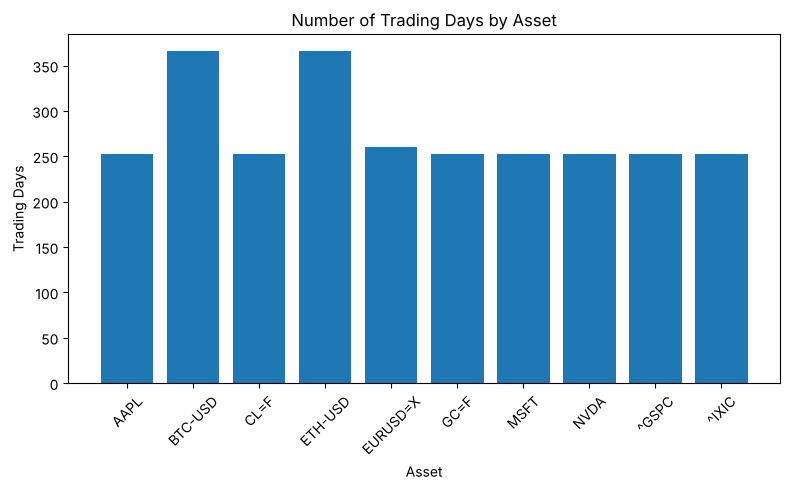

In [13]:
plt.figure(figsize=(8,5))

plt.bar(
    trading_days_df["Ticker"],
    trading_days_df["Trading Days"]
)

plt.title("Number of Trading Days by Asset")
plt.xlabel("Asset")
plt.ylabel("Trading Days")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/trading_days.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The dataset contains a consistent number of observations for most assets.

#### Figure 2 – Average Closing Price

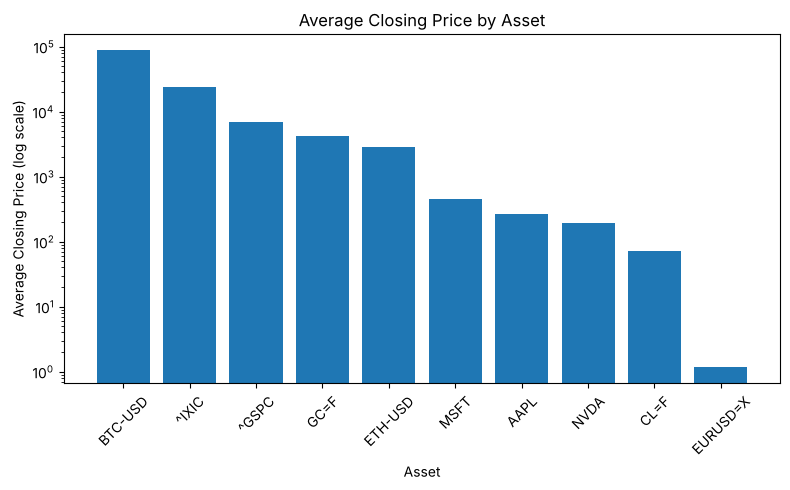

In [14]:
plt.figure(figsize=(8,5))

plt.bar(
    average_closing_price_df["Ticker"],
    average_closing_price_df["Average Closing Price"]
)

plt.title("Average Closing Price by Asset")
plt.xlabel("Asset")
plt.yscale("log")  # prices range from ~1 (EUR/USD) to ~100,000 (Bitcoin)
plt.ylabel("Average Closing Price (log scale)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/average_closing_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Nominal price levels differ substantially between asset classes (the vertical axis is logarithmic).

#### Figure 3 – Average Daily Return

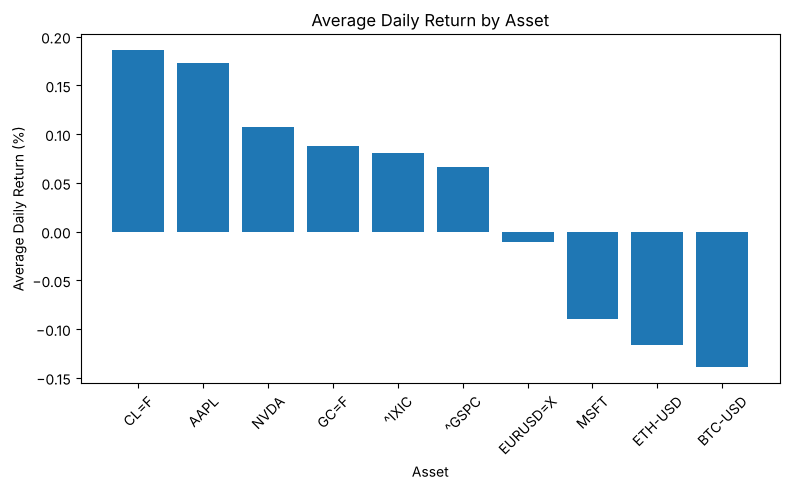

In [15]:
plt.figure(figsize=(8,5))

plt.bar(
    average_daily_return_df["Ticker"],
    average_daily_return_df["Average Daily Return"] * 100  # fraction -> %
)

plt.title("Average Daily Return by Asset")
plt.xlabel("Asset")
plt.ylabel("Average Daily Return (%)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/average_daily_return.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Average daily returns remain relatively small despite occasional large daily movements.

#### Figure 4 – Average Trading Volume

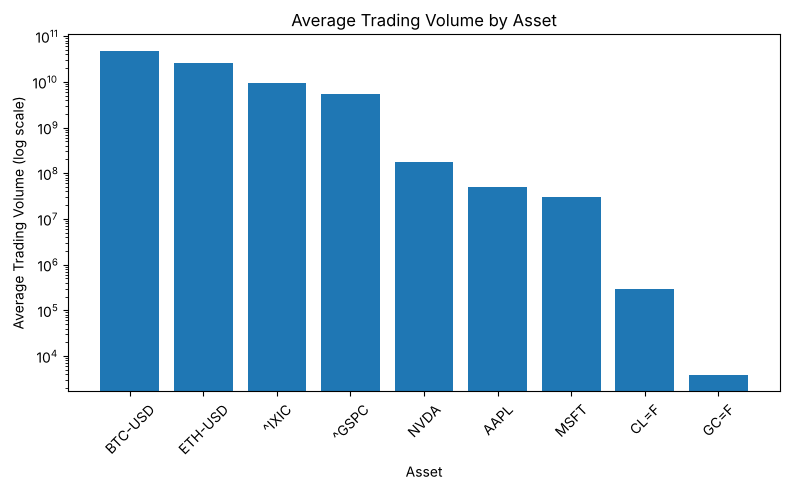

In [16]:
# EUR/USD is left out: Yahoo Finance reports no volume for FX pairs (always 0).
volume_plot_df = average_volume_df[average_volume_df["Average Trading Volume"] > 0]

plt.figure(figsize=(8,5))

plt.bar(
    volume_plot_df["Ticker"],
    volume_plot_df["Average Trading Volume"]
)

plt.yscale("log")  # volume units differ by asset class (shares vs. USD)
plt.title("Average Trading Volume by Asset")
plt.xlabel("Asset")
plt.ylabel("Average Trading Volume (log scale)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/average_trading_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Trading activity varies considerably between markets. The axis is logarithmic, EUR/USD is omitted because Yahoo Finance reports no FX volume, and units differ by asset class (USD for cryptocurrencies, shares for stocks).

#### Figure 5 – Volatility

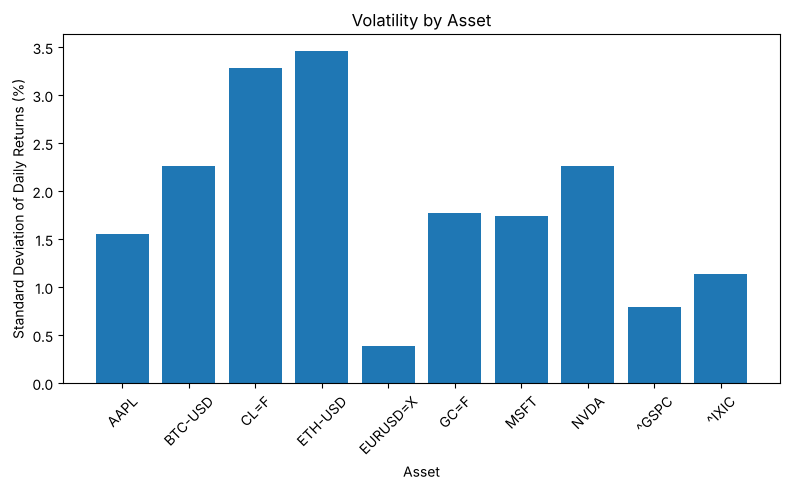

In [17]:
plt.figure(figsize=(8,5))

plt.bar(
    volatility_df["Ticker"],
    volatility_df["Volatility"] * 100  # fraction -> %
)

plt.title("Volatility by Asset")
plt.xlabel("Asset")
plt.ylabel("Standard Deviation of Daily Returns (%)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

More volatile assets display larger day-to-day price fluctuations.

### 9. Key Findings

This analysis explored one year of daily market data (23 July 2025 – 23 July 2026) for equities, cryptocurrencies, commodities, stock indices, and foreign exchange using SQL and Python.

The main findings are:

* The ETL pipeline collected and stored a consistent dataset for all ten assets in SQLite (2,756 rows).
* Cryptocurrencies contain more observations (366) than stocks, indices and commodities (252), because they trade every day. EUR/USD has 260.
* Bitcoin had the highest nominal closing price (about 124,753 at its peak), although nominal prices are not directly comparable across different asset classes.
* Crude Oil (+0.19%) and Apple (+0.17%) had the highest average daily returns, while Bitcoin (−0.14%) and Ethereum (−0.12%) had the lowest.
* Ethereum recorded the largest single-day gain (+14.4% on 22 Aug 2025) and Crude Oil the largest single-day loss (−16.4% on 8 Apr 2026).
* Ethereum was the most volatile asset (daily standard deviation of 3.46%), followed by Crude Oil (3.28%), whereas EUR/USD (0.39%), the S&P 500 (0.80%) and the NASDAQ Composite (1.14%) were the least volatile.
* Bitcoin and Ethereum show the highest average trading volume, but volumes are not comparable across asset classes: cryptocurrency volume is reported in USD, stock volume in shares, and Yahoo Finance reports none for EUR/USD.

### 10. Overall Conclusion

This notebook demonstrated how SQL and Python can be combined to analyze historical financial market data stored in SQLite. Using SQL aggregation functions together with pandas and Matplotlib, key characteristics of different asset classes—including prices, returns, trading activity, and volatility—were successfully explored.

The insights obtained in this analysis provide the foundation for the final stage of the project: building an interactive Tableau dashboard that enables users to explore market performance through dynamic visualizations.

In [18]:
connection.close()

The SQL analysis is now complete. The next stage of the project focuses on creating an interactive Tableau dashboard using the processed data.